In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Version of numpy: ", np.__version__)
print("Version of pandas: ", pd.__version__)
print("Version of matplotlib: ", plt.matplotlib.__version__)

Version of numpy:  2.3.5
Version of pandas:  2.3.3
Version of matplotlib:  3.10.6


In [5]:
df = pd.read_csv("cleaned_sales.csv")
df

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Duplicate_Order_ID,Order_Year,Order_Month,Order_Day,Age_Group,Sales_Outlier
0,ORD100002,25-02-2025,CUST5529,Customer_227,30,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,False,2025,2,25,Adult,False
1,ORD100003,14-10-2025,CUST3127,Customer_182,63,Male,Bengaluru,Book,Education,5,27906.16,139530.80,False,2025,10,14,Senior,False
2,ORD100004,13-05-2025,CUST8887,Customer_487,62,Female,Bengaluru,Book,Education,8,37491.06,299928.48,False,2025,5,13,Senior,False
3,ORD100005,02-12-2025,CUST2515,Customer_470,65,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,False,2025,12,2,Senior,False
4,ORD100006,20-11-2025,CUST4796,Customer_380,44,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,False,2025,11,20,Middle_Aged,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,ORD100997,07-11-2025,CUST6410,Customer_301,61,Male,Gaya,Laptop,Electronics,9,35405.54,318649.86,False,2025,11,7,Senior,False
996,ORD100998,03-09-2025,CUST7618,Customer_154,25,Male,Gaya,Shoes,Fashion,5,18454.65,92273.25,False,2025,9,3,Young,False
997,ORD100999,30-09-2025,CUST9544,Customer_140,62,Female,Hyderabad,Laptop,Electronics,9,12971.59,116744.31,False,2025,9,30,Senior,False
998,ORD101000,21-02-2025,CUST9501,Customer_241,41,Male,Delhi,Mobile,Electronics,9,2879.01,25911.09,False,2025,2,21,Middle_Aged,False


In [6]:
df.shape

(1000, 18)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Order_ID            1000 non-null   object 
 1   Order_Date          1000 non-null   object 
 2   Customer_ID         1000 non-null   object 
 3   Customer_Name       1000 non-null   object 
 4   Age                 1000 non-null   int64  
 5   Gender              1000 non-null   object 
 6   City                1000 non-null   object 
 7   Product             1000 non-null   object 
 8   Category            1000 non-null   object 
 9   Quantity            1000 non-null   int64  
 10  Unit_Price          1000 non-null   float64
 11  Total_Sales         1000 non-null   float64
 12  Duplicate_Order_ID  1000 non-null   bool   
 13  Order_Year          1000 non-null   int64  
 14  Order_Month         1000 non-null   int64  
 15  Order_Day           1000 non-null   int64  
 16  Age_Gro

In [12]:
# convert the 'Order_Date' column to datetime format
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce') # error='coerce' will convert invalid dates to NaT (Not a Time) 

print("After converting 'Order_Date' to datetime format:")
print("Dataset Shape: ", df.shape)
display(df.head()) # display the first 5 rows of the DataFrame

After converting 'Order_Date' to datetime format:
Dataset Shape:  (1000, 18)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Duplicate_Order_ID,Order_Year,Order_Month,Order_Day,Age_Group,Sales_Outlier
0,ORD100002,2025-02-25,CUST5529,Customer_227,30,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,False,2025,2,25,Adult,False
1,ORD100003,2025-10-14,CUST3127,Customer_182,63,Male,Bengaluru,Book,Education,5,27906.16,139530.80,False,2025,10,14,Senior,False
2,ORD100004,2025-05-13,CUST8887,Customer_487,62,Female,Bengaluru,Book,Education,8,37491.06,299928.48,False,2025,5,13,Senior,False
3,ORD100005,2025-12-02,CUST2515,Customer_470,65,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,False,2025,12,2,Senior,False
4,ORD100006,2025-11-20,CUST4796,Customer_380,44,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,False,2025,11,20,Middle_Aged,False


In [15]:
# Descriptive statistics
display(
    df[[
        "Age",
        "Quantity",
        "Unit_Price",
        "Total_Sales"
    ]].describe()
)

,Age,Quantity,Unit_Price,Total_Sales
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,41.353000,5.435000,25486.783410,139399.439650
std,13.683626,2.838632,14179.402361,114100.051546
min,18.000000,1.000000,145.780000,437.340000
25%,30.000000,3.000000,13895.722500,47066.632500
50%,41.000000,5.000000,25398.740000,108594.025000
75%,53.000000,8.000000,37512.382500,203722.882500
max,65.000000,10.000000,49997.530000,493677.500000


In [16]:
# Key business metrics
total_revenue = df["Total_Sales"].sum() # Calculate total revenue by summing the "Total_Sales" column
total_orders = df["Order_ID"].nunique() # Calculate the number of unique order IDs
total_customers = df["Customer_ID"].nunique() # Calculate the number of unique customer IDs
total_units = df["Quantity"].sum() # Calculate total units sold by summing the "Quantity" column
average_sales = df["Total_Sales"].mean() # Calculate average sales per row by taking the mean of the "Total_Sales" column

print("Total Revenue:", round(total_revenue, 2)) # Round the total revenue to 2 decimal places for better readability
print("Unique Order IDs:", total_orders) # Print the number of unique order IDs
print("Unique Customers:", total_customers) # Print the number of unique customer IDs
print("Total Units Sold:", total_units) # Print the total units sold
print("Average Sales per Row:", round(average_sales, 2)) # Round the average sales to 2 decimal places for better readability

Total Revenue: 139399439.65
Unique Order IDs: 992
Unique Customers: 947
Total Units Sold: 5435
Average Sales per Row: 139399.44


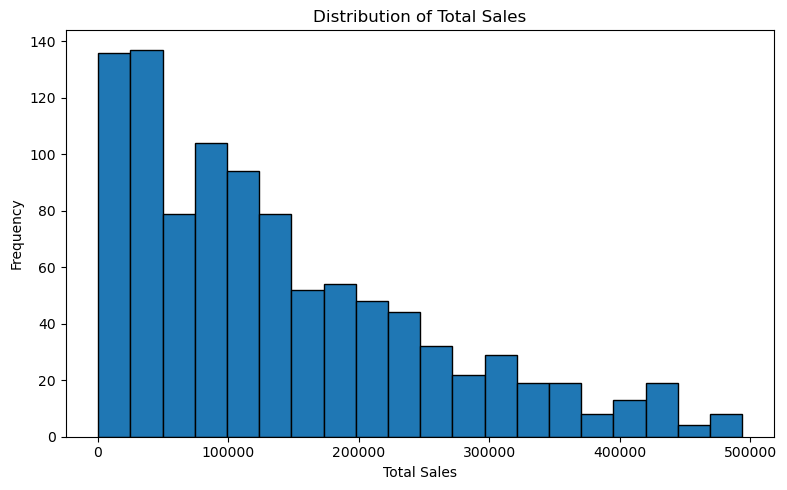

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Total_Sales"].dropna(), # 
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Frequency") # iska matlab hai ki kitni baar ye value aayi hai

plt.tight_layout() # iska matlab hai ki layout ko adjust karna taki sab kuch fit ho jaye aur overlap na ho
plt.show() # graph ko display karne ke liye

Category
Electronics    50778581.70
Education      25031689.40
Grocery        22231711.28
Furniture      21521561.48
Fashion        19835895.79
Name: Total_Sales, dtype: float64


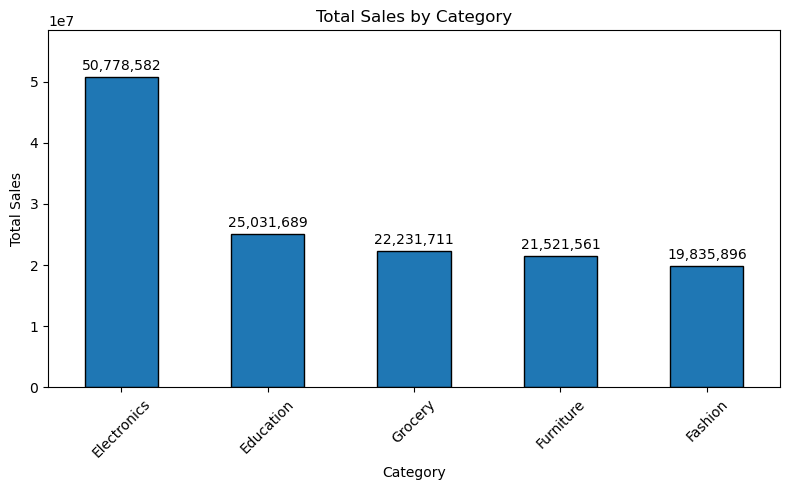

In [19]:
category_sales = (
    df.groupby("Category")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

ax = category_sales.plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)

ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
ax.margins(y=0.15)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
categorical_cols = ["Gender", "City", "Product", "Category"]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts().head(10))


--- Gender ---


Gender
Male      511
Female    489
Name: count, dtype: int64


--- City ---


City
Patna        135
Kolkata      133
Mumbai       131
Hyderabad    125
Delhi        125
Bengaluru    122
Gaya         117
Pune          99
Unknown       13
Name: count, dtype: int64


--- Product ---


Product
Mobile    184
Book      178
Laptop    170
Chair     159
Shoes     156
Rice      153
Name: count, dtype: int64


--- Category ---


Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64

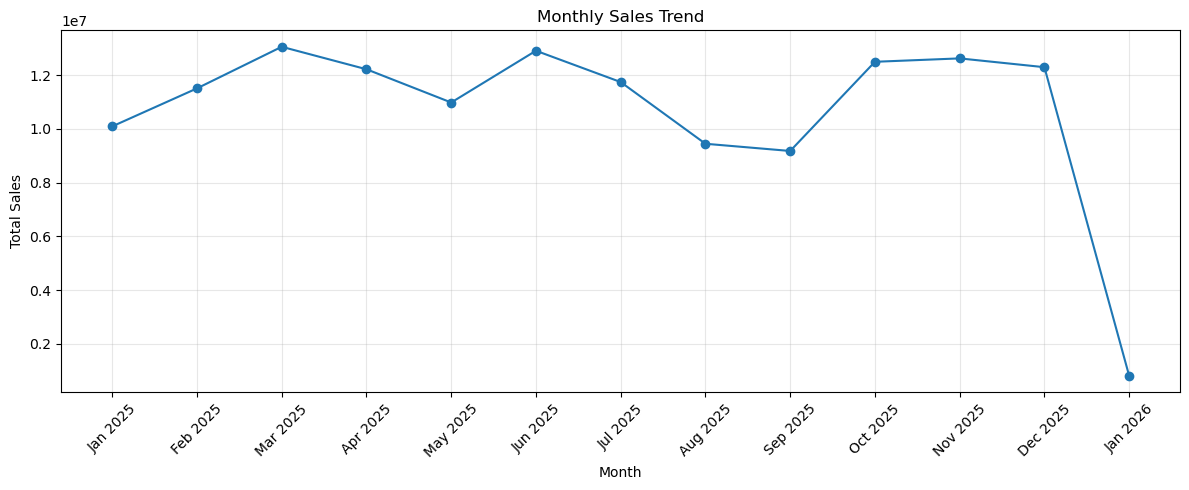

In [25]:

# Month-wise total sales calculate karein
monthly_sales = (
    df.dropna(subset=["Order_Date"])
      .groupby(df["Order_Date"].dt.to_period("M"))["Total_Sales"]
      .sum()
      .sort_index()
)
# Month name with year
month_labels = monthly_sales.index.strftime("%b %Y") # %b & %Y ka matlab hai ki month ka short name aur year ko display karna AND (%B & %y ) iska matlab hai ki month ka full name aur year ko display karna


# Chart banayein
plt.figure(figsize=(12, 5))
plt.plot(
    month_labels,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

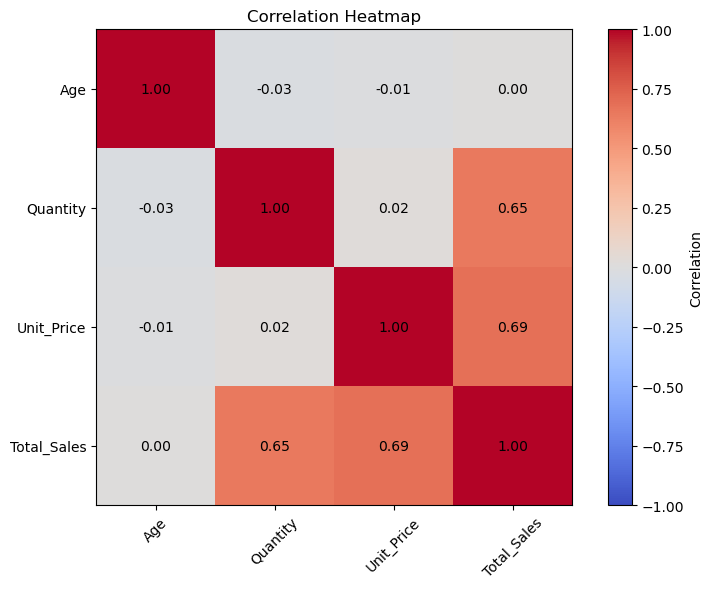

In [26]:


# Numerical columns select karein
numeric_cols = [
    "Age",
    "Quantity",
    "Unit_Price",
    "Total_Sales"
]

# Correlation calculate karein
correlation = df[numeric_cols].corr()

# Heatmap banayein
plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

# Values show karein
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()